In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("Environment setup successful!")

Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1
Environment setup successful!


# Predict Loan Defaulter — Data Exploration

## Objective
Explore a public credit default dataset and understand the
features used to predict whether a client defaults on payment.

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project and dataset paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "default of credit card clients.xls"

# Load the dataset
df = pd.read_excel(DATA_PATH, header=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

C:\Users\Sudhanshu\AppData\Local\Temp\ipykernel_21952\1208154094.py:13: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(DATA_PATH, header=1)


Dataset loaded successfully!
Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
# Inspect the structure
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe().T)

Rows and columns: (30000, 25)

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       300

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [4]:
TARGET = "default payment next month"

print(df[TARGET].value_counts())

print("\nTarget distribution (%):")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

default payment next month
0    23364
1     6636
Name: count, dtype: int64

Target distribution (%):
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


In [5]:
print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


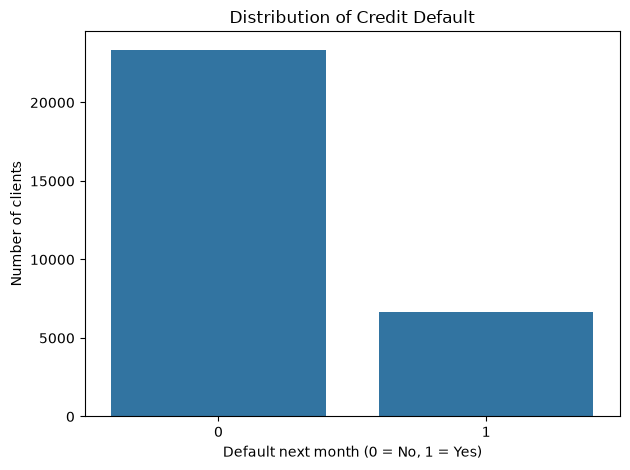

In [6]:
ax = sns.countplot(data=df, x=TARGET)

ax.set_title("Distribution of Credit Default")
ax.set_xlabel("Default next month (0 = No, 1 = Yes)")
ax.set_ylabel("Number of clients")

plt.tight_layout()
plt.show()

## 2.6 Data Quality Checks

Check for missing values, duplicate records, duplicate IDs,
and unexpected values in the target column.

In [7]:
print("Missing values by column:")

missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

if missing_values.sum() == 0:
    print("No missing values found.")

Missing values by column:


Series([], dtype: int64)

No missing values found.


In [8]:
print("Duplicate rows:", df.duplicated().sum())

if "ID" in df.columns:
    print("Duplicate IDs:", df["ID"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


In [9]:
print("Target column:", TARGET)

print("\nUnique target values:")
print(sorted(df[TARGET].dropna().unique()))

print("\nTarget value counts:")
print(df[TARGET].value_counts(dropna=False))

Target column: default payment next month

Unique target values:
[np.int64(0), np.int64(1)]

Target value counts:
default payment next month
0    23364
1     6636
Name: count, dtype: int64


In [10]:
print("Dataset shape:", df.shape)

print("\nData types:")
display(df.dtypes)

print("\nStatistical summary:")
display(df.describe().T)

Dataset shape: (30000, 25)

Data types:


ID                            int64
LIMIT_BAL                     int64
SEX                           int64
EDUCATION                     int64
MARRIAGE                      int64
AGE                           int64
PAY_0                         int64
PAY_2                         int64
PAY_3                         int64
PAY_4                         int64
PAY_5                         int64
PAY_6                         int64
BILL_AMT1                     int64
BILL_AMT2                     int64
BILL_AMT3                     int64
BILL_AMT4                     int64
BILL_AMT5                     int64
BILL_AMT6                     int64
PAY_AMT1                      int64
PAY_AMT2                      int64
PAY_AMT3                      int64
PAY_AMT4                      int64
PAY_AMT5                      int64
PAY_AMT6                      int64
default payment next month    int64
dtype: object


Statistical summary:


,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


## Data Quality Summary

- **Dataset size:** 30,000 records and 25 columns.
- **Target variable:** `default payment next month`.
- **Target values:** `0` (no default) and `1` (default).
- **Non-default records:** 23,364 (77.88%).
- **Default records:** 6,636 (22.12%).
- **Missing values:** None found.
- **Duplicate rows:** 0.
- **Duplicate IDs:** 0.
- **Initial observation:** The target classes are imbalanced, with fewer default cases than non-default cases. This imbalance should be considered when evaluating the machine learning model.

# Step 3: Exploratory Data Analysis (EDA)

Explore borrower characteristics, repayment history, credit limits,
and payment behaviour to understand patterns associated with default.

In [11]:
# Calculate the overall default rate
default_rate = df[TARGET].mean() * 100
print(f"Overall default rate: {default_rate:.2f}%")

# Compare borrower characteristics by default status
features = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "PAY_AMT1"
]

display(
    df.groupby(TARGET)[features]
      .mean()
      .round(2)
)

Overall default rate: 22.12%


,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1
default payment next month,,,,
0,178099.73,35.42,51994.23,6307.34
1,130109.66,35.73,48509.16,3397.04


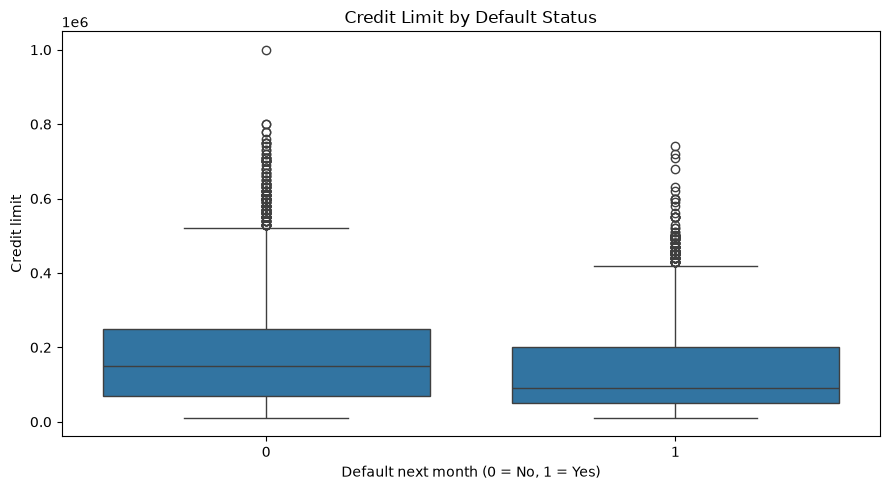

In [12]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=TARGET,
    y="LIMIT_BAL"
)

plt.title("Credit Limit by Default Status")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Credit limit")

plt.tight_layout()
plt.show()

In [13]:
# Compare repayment status by default outcome
repayment_features = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

display(
    df.groupby(TARGET)[repayment_features]
      .mean()
      .round(2)
)

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
default payment next month,,,,,,
0,-0.21,-0.30,-0.32,-0.36,-0.39,-0.41
1,0.67,0.46,0.36,0.25,0.17,0.11


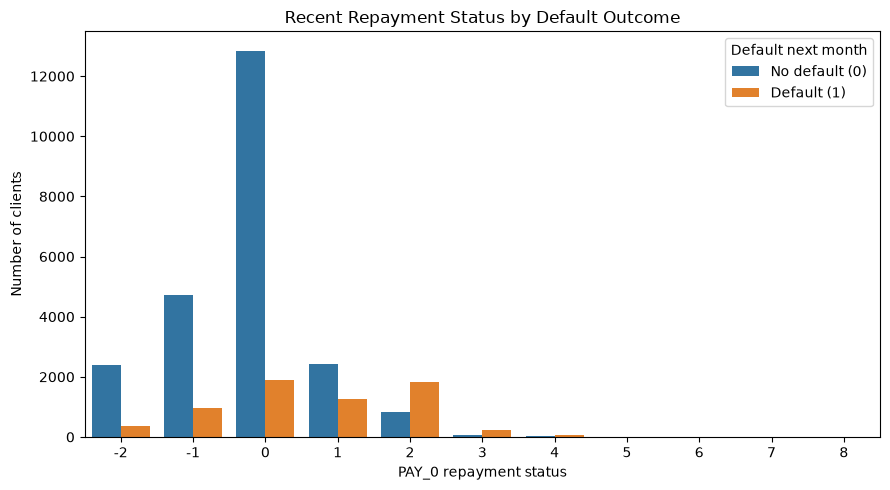

In [14]:
# Compare recent repayment status by default outcome
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="PAY_0",
    hue=TARGET
)

plt.title("Recent Repayment Status by Default Outcome")
plt.xlabel("PAY_0 repayment status")
plt.ylabel("Number of clients")
plt.legend(
    title="Default next month",
    labels=["No default (0)", "Default (1)"]
)

plt.tight_layout()
plt.show()

In [15]:
# Calculate default rate for each recent repayment status
default_rate_by_pay0 = (
    df.groupby("PAY_0")[TARGET]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "customer_count",
          "mean": "default_rate"
      })
)

default_rate_by_pay0["default_rate"] *= 100

display(default_rate_by_pay0.round(2))

,customer_count,default_rate
PAY_0,,
-2,2759,13.23
-1,5686,16.78
0,14737,12.81
1,3688,33.95
2,2667,69.14
3,322,75.78
4,76,68.42
5,26,50.00
6,11,54.55


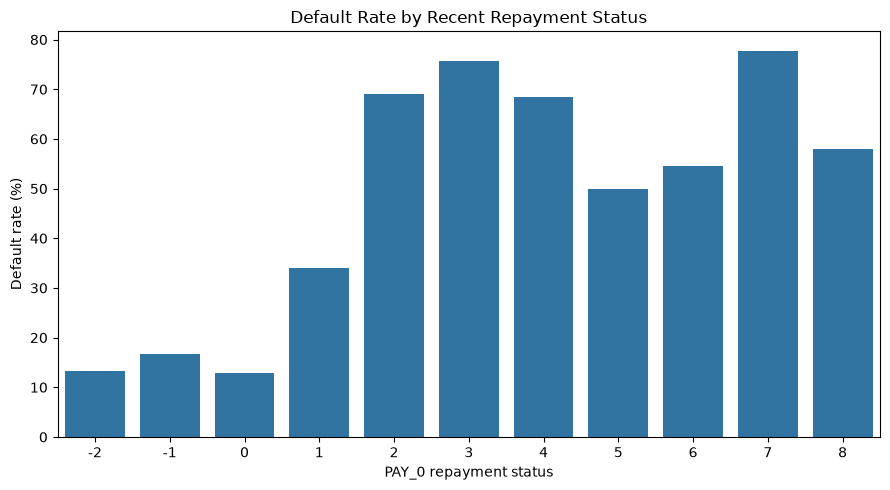

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=default_rate_by_pay0.index,
    y=default_rate_by_pay0["default_rate"]
)

plt.title("Default Rate by Recent Repayment Status")
plt.xlabel("PAY_0 repayment status")
plt.ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

### Repayment History Analysis — Key Findings

- Repayment-status averages differ substantially between customers who defaulted and those who did not.
- `PAY_0`, representing the most recent repayment status, shows the largest difference between the two groups.
- Recent repayment behaviour appears to be a potentially valuable predictor of future credit default.
- Further analysis and model evaluation are required to determine the predictive importance of individual features.

### Default Rate by Recent Repayment Status — Key Findings

- The overall next-month default rate is 22.12%.
- Default rates vary substantially across `PAY_0` repayment-status categories.
- Several categories associated with repayment delays show considerably higher default rates than the overall dataset.
- `PAY_0` appears to be a promising feature for predicting credit default.
- Category-level customer counts should be considered when interpreting default rates, particularly for less frequent categories.

**Conclusion:** Recent repayment behaviour appears to be an important signal for credit default risk and warrants further evaluation during model development.

In [17]:
# Default rate by education level
education_analysis = (
    df.groupby("EDUCATION")[TARGET]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "customer_count",
          "mean": "default_rate"
      })
)

education_analysis["default_rate"] *= 100

display(education_analysis.round(2))

,customer_count,default_rate
EDUCATION,,
0,14,0.00
1,10585,19.23
2,14030,23.73
3,4917,25.16
4,123,5.69
5,280,6.43
6,51,15.69


In [18]:
# Default rate by marital status
marriage_analysis = (
    df.groupby("MARRIAGE")[TARGET]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "customer_count",
          "mean": "default_rate"
      })
)

marriage_analysis["default_rate"] *= 100

display(marriage_analysis.round(2))

,customer_count,default_rate
MARRIAGE,,
0,54,9.26
1,13659,23.47
2,15964,20.93
3,323,26.01


In [19]:
# Compare age by default outcome
age_summary = (
    df.groupby(TARGET)["AGE"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

display(age_summary)

,count,mean,median,min,max
default payment next month,,,,,
0,23364,35.42,34.0,21,79
1,6636,35.73,34.0,21,75


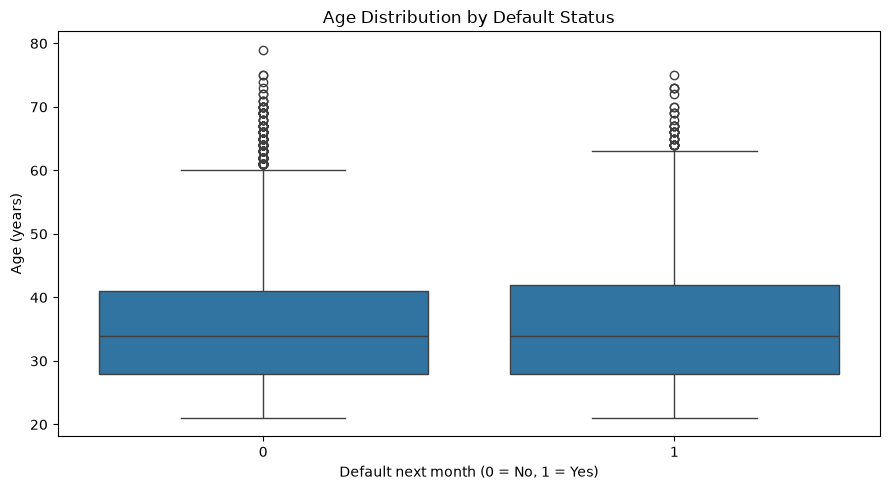

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=TARGET,
    y="AGE"
)

plt.title("Age Distribution by Default Status")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Age (years)")

plt.tight_layout()
plt.show()

In [21]:
# Compare age by default outcome
age_summary = (
    df.groupby(TARGET)["AGE"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

display(age_summary)

,count,mean,median,min,max
default payment next month,,,,,
0,23364,35.42,34.0,21,79
1,6636,35.73,34.0,21,75


## Exploratory Data Analysis — Summary

### Key Findings

- **Target distribution:** 22.12% of customers defaulted the following month, indicating class imbalance.
- **Credit limit:** Customers who defaulted had a lower average credit limit than non-defaulters.
- **Payment behaviour:** Average payment amounts were lower among customers who defaulted.
- **Repayment history:** `PAY_0` showed a substantial association with next-month default rates, making recent repayment status a promising predictive feature.
- **Education:** Default rates varied across education categories; categories with small sample sizes require cautious interpretation.
- **Marital status:** Default rates differed across marital-status categories, although some categories contained relatively few customers.
- **Age:** The age distributions overlapped considerably between default groups, suggesting that age alone may have limited predictive value.

### Conclusion

Repayment history and payment behaviour appear promising for predicting credit default. These observations will guide feature preparation and model development. Feature importance and predictive performance must be confirmed using a properly separated test set.

# Step 4: Data Preprocessing

Prepare the dataset for machine learning by separating the input features from the target variable, reviewing data types, and checking categorical values before model training.

In [22]:
# Separate features and target
TARGET = "default payment next month"

# The ID column identifies customers; it is not a predictive feature.
X = df.drop(columns=[TARGET, "ID"])
y = df[TARGET].astype(int)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature data types:")
display(X.dtypes)

print("\nUnique values in categorical columns:")
for column in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"{column}: {sorted(X[column].unique())}")

Feature matrix shape: (30000, 23)
Target vector shape: (30000,)

Target distribution:
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Feature data types:


LIMIT_BAL    int64
SEX          int64
EDUCATION    int64
MARRIAGE     int64
AGE          int64
PAY_0        int64
PAY_2        int64
PAY_3        int64
PAY_4        int64
PAY_5        int64
PAY_6        int64
BILL_AMT1    int64
BILL_AMT2    int64
BILL_AMT3    int64
BILL_AMT4    int64
BILL_AMT5    int64
BILL_AMT6    int64
PAY_AMT1     int64
PAY_AMT2     int64
PAY_AMT3     int64
PAY_AMT4     int64
PAY_AMT5     int64
PAY_AMT6     int64
dtype: object


Unique values in categorical columns:
SEX: [np.int64(1), np.int64(2)]
EDUCATION: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MARRIAGE: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


### Step 4.1: Train-Test Split

Split the dataset into training and testing subsets using stratified sampling to preserve the target class distribution. The test set will remain separate from model training and preprocessing decisions.

In [23]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training feature shape: (24000, 23)
Testing feature shape: (6000, 23)

Training target distribution (%):
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

Testing target distribution (%):
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


### Step 4.2: Build the Baseline Classification Pipeline

Create a scikit-learn pipeline that preprocesses numerical and categorical features and trains a Logistic Regression classifier. Fitting the preprocessing steps within the pipeline prevents information from the test set leaking into model training.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Define categorical and numerical features
categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]

numerical_features = [
    column for column in X_train.columns
    if column not in categorical_features
]

# Preprocess numerical and categorical features separately
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Create the complete machine-learning pipeline
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Train the model using training data only
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression model trained successfully.")
print("Numerical features:", len(numerical_features))
print("Categorical features:", categorical_features)

Baseline Logistic Regression model trained successfully.
Numerical features: 20
Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']


### Step 4.2: Build the Baseline Classification Pipeline

Create a scikit-learn pipeline that preprocesses numerical and categorical features and trains a Logistic Regression classifier. Fitting the preprocessing steps within the pipeline prevents information from the test set leaking into model training.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Define categorical and numerical features
categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]

numerical_features = [
    column for column in X_train.columns
    if column not in categorical_features
]

# Preprocess numerical and categorical features separately
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Create the complete machine-learning pipeline
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Train the model using training data only
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression model trained successfully.")
print("Numerical features:", len(numerical_features))
print("Categorical features:", categorical_features)

Baseline Logistic Regression model trained successfully.
Numerical features: 20
Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']


### Step 4.3: Evaluate the Baseline Model

Evaluate the Logistic Regression model on the held-out test set using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix. These metrics provide a more complete assessment than accuracy alone, particularly because the target classes are imbalanced.

Baseline Logistic Regression — Test Results
---------------------------------------------
Accuracy    : 0.8088
Precision   : 0.6923
Recall      : 0.2442
F1-score    : 0.3610
ROC-AUC     : 0.7100

Classification Report:
              precision    recall  f1-score   support

  No Default       0.82      0.97      0.89      4673
     Default       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.76      0.61      0.62      6000
weighted avg       0.79      0.81      0.77      6000



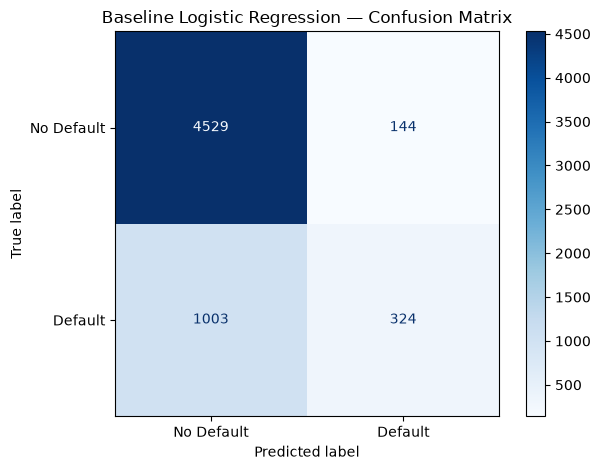

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions on unseen test data
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

print("Baseline Logistic Regression — Test Results")
print("-" * 45)

for metric, score in metrics.items():
    print(f"{metric:12}: {score:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

### Step 4.4: Experiment with the Classification Threshold

Evaluate how changing the classification threshold affects default prediction. A lower threshold may improve recall but can also increase false positives. Threshold selection should reflect the relative costs of missed defaults and unnecessary risk flags.

In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Use the probabilities already generated on the test set
thresholds = [0.50, 0.40, 0.30, 0.20]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score
0,0.5,0.6923,0.2442,0.3610
1,0.4,0.6314,0.3783,0.4731
2,0.3,0.5518,0.4574,0.5002
3,0.2,0.3195,0.6895,0.4366


### Step 5: Compare Baseline Models

Train a Random Forest classifier using the same training and test split. Compare its predictive performance with Logistic Regression using precision, recall, F1-score, and ROC-AUC.

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create the Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train using training data only
rf_model.fit(X_train, y_train)

# Evaluate on the same held-out test set
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest — Test Results")
print("-" * 35)
print(f"Accuracy : {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, rf_prob):.4f}")

Random Forest — Test Results
-----------------------------------
Accuracy : 0.7920
Precision: 0.5299
Recall   : 0.5268
F1-score : 0.5283
ROC-AUC  : 0.7680


### Step 5.1: Feature Importance Analysis

Examine the Random Forest model's feature importance scores to identify which input features contribute most to its predictions. These scores describe the model's use of features and should not be interpreted as causal effects.

Top 15 features by Random Forest importance:


,feature,importance
0,num__PAY_0,0.1078
1,num__BILL_AMT1,0.0580
2,num__LIMIT_BAL,0.0562
3,num__PAY_AMT1,0.0521
4,num__BILL_AMT2,0.0516
5,num__AGE,0.0505
6,num__PAY_AMT2,0.0501
7,num__BILL_AMT3,0.0485
8,num__PAY_2,0.0484
9,num__PAY_AMT3,0.0479


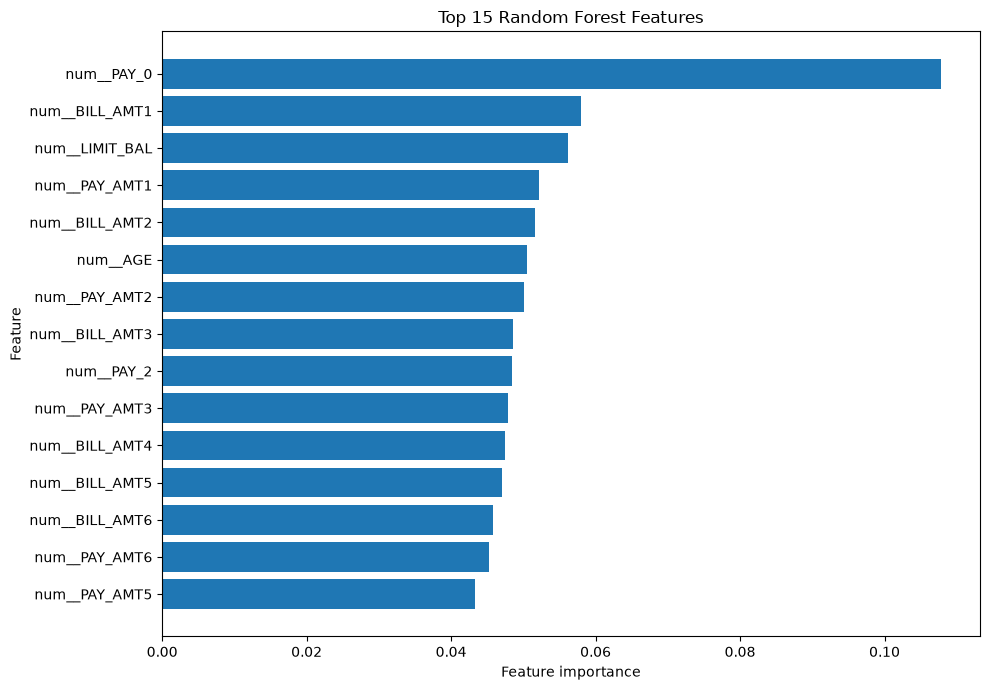

In [29]:
# Extract the trained Random Forest and its preprocessing transformer
rf_classifier = rf_model.named_steps["classifier"]
rf_preprocessor = rf_model.named_steps["preprocessor"]

# Retrieve the feature names after preprocessing
feature_names = rf_preprocessor.get_feature_names_out()

# Create a sorted feature-importance table
feature_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": rf_classifier.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 features by Random Forest importance:")
display(feature_importance.head(15).round(4))

# Plot the top 15 features
top_features = feature_importance.head(15).sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["feature"],
    top_features["importance"]
)
plt.title("Top 15 Random Forest Features")
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Step 5.2: Random Forest Hyperparameter Tuning

Use stratified cross-validation on the training set to compare Random Forest configurations. Select the configuration based on mean validation F1-score, while also reviewing recall and ROC-AUC. Keep the test set separate for final evaluation.

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# Create a fresh pipeline for tuning
rf_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                class_weight="balanced",
                n_jobs=1
            )
        )
    ]
)

# Compare a small set of configurations
param_grid = {
    "classifier__n_estimators": [150, 300],
    "classifier__max_depth": [None, 15],
    "classifier__min_samples_leaf": [2, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "roc_auc": "roc_auc"
    },
    refit="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

# Tune on training data only
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print(f"\nBest mean cross-validation F1-score: "
      f"{grid_search.best_score_:.4f}")

# Show the best configurations
cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results[
        [
            "param_classifier__n_estimators",
            "param_classifier__max_depth",
            "param_classifier__min_samples_leaf",
            "mean_test_f1",
            "mean_test_recall",
            "mean_test_roc_auc"
        ]
    ]
    .sort_values("mean_test_f1", ascending=False)
    .head(8)
    .round(4)
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 150}

Best mean cross-validation F1-score: 0.5448


,param_classifier__n_estimators,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_test_f1,mean_test_recall,mean_test_roc_auc
2,150,None,5,0.5448,0.5803,0.7812
7,300,15,5,0.5446,0.5858,0.7839
5,300,15,2,0.5436,0.5643,0.7812
3,300,None,5,0.5430,0.5777,0.7817
4,150,15,2,0.5428,0.5639,0.7802
6,150,15,5,0.5428,0.5860,0.7835
1,300,None,2,0.5381,0.5364,0.7785
0,150,None,2,0.5375,0.5370,0.7774


### Step 5.3: Evaluate the Tuned Random Forest

Evaluate the best Random Forest configuration selected through stratified cross-validation on the held-out test set. Compare its precision, recall, F1-score, ROC-AUC, and confusion matrix with the original baseline results.

Tuned Random Forest — Test Results
----------------------------------------
Accuracy    : 0.7803
Precision   : 0.5030
Recall      : 0.5637
F1-score    : 0.5316
ROC-AUC     : 0.7717

Classification Report:
              precision    recall  f1-score   support

  No Default       0.87      0.84      0.86      4673
     Default       0.50      0.56      0.53      1327

    accuracy                           0.78      6000
   macro avg       0.69      0.70      0.69      6000
weighted avg       0.79      0.78      0.78      6000



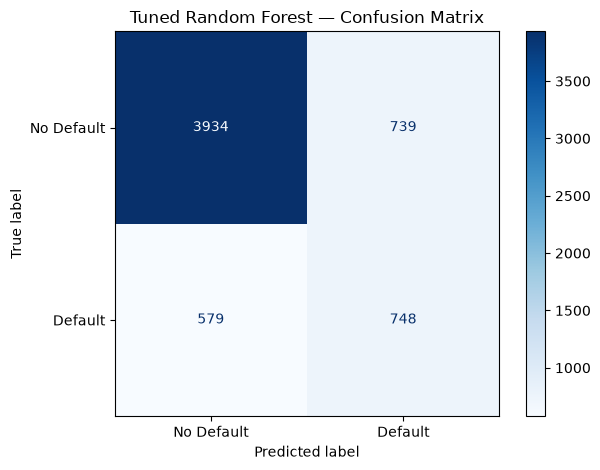

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Retrieve the best tuned model
best_rf_model = grid_search.best_estimator_

# Generate test predictions
tuned_pred = best_rf_model.predict(X_test)
tuned_prob = best_rf_model.predict_proba(X_test)[:, 1]

# Calculate test metrics
tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_pred),
    "Precision": precision_score(
        y_test, tuned_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, tuned_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, tuned_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, tuned_prob)
}

print("Tuned Random Forest — Test Results")
print("-" * 40)

for metric, score in tuned_metrics.items():
    print(f"{metric:12}: {score:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("Tuned Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

In [33]:
from pathlib import Path
import joblib

# Define the project models directory
PROJECT_ROOT = Path.cwd().parent
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete pipeline, including preprocessing
MODEL_PATH = MODELS_DIR / "credit_default_model.joblib"

joblib.dump(best_rf_model, MODEL_PATH)

print(f"Model saved successfully: {MODEL_PATH}")
print(f"Model file exists: {MODEL_PATH.exists()}")

Model saved successfully: c:\Users\Sudhanshu\Projects\predict-loan-defaulter\models\credit_default_model.joblib
Model file exists: True


In [34]:

from pathlib import Path
import joblib

model_path = (
    Path.cwd().parent
    / "models"
    / "credit_default_model.joblib"
)

model = joblib.load(model_path)

print("Expected feature count:", len(model.feature_names_in_))
print("Expected features:")
print(list(model.feature_names_in_))


Expected feature count: 23
Expected features:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
